# Cumulative CDR by 2100 across adoption-rate scenarios

- **Control** -- the GCAM schedule (a single scenario, no `k` range).
- **`nearterm-gcam-first10yrs`**, **`cdrfyi-sales`**, **`cdrfyi-deliveries`** -- three `C0`/`t0`
  reference-capacity cases, each run at two growth rates (`k_gcam`, `k_nemetMedian`).


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
# --- [ SCEPTER representative run ] ---
EXP_SET_MAIN = "exe_central1p5"
idx          = "001"
SAVE_GROUP   = "gcam"
EXP_GROUP    = "gcam_opr_full2_cec1"

fn_cdr_sum   = "ds_cdr_globalScaling_constApp_SUM.zarr"

# --- [ schedule naming, matching create-synthetic-s-curves.ipynb's s_curve_param_dict keys ] ---
CONTROL_SCHEDULE = "exe_central1p5"       # real GCAM baseline -- single k, no k_gcam/k_nemetMedian split
C0T0_CASES = ["nearterm-gcam-first10yrs", "cdrfyi-sales", "cdrfyi-deliveries"]
K_LOW, K_HIGH = "k_nemetMedian", "k_gcam"  # the two k cases each C0t0 case was run at
L_CASES = ["L_gcam", "L2.0Gt", "L0.5Gt"]   # one panel per L case, largest asymptote first


def schedule_name(c0t0, k, L_case):
    return f"{c0t0}_{k}_{L_case}"


# GCAM-native schedule per L (hollow markers + dashed lines in the main figure);
# None = no postprocessed run on S3 yet, so that L is plotted without a native reference
NATIVE_SCHEDULE = {"L_gcam": CONTROL_SCHEDULE, "L2.0Gt": None, "L0.5Gt": "gcam-native_L0.5Gt"}

ALL_SCHEDULES = list(dict.fromkeys(
    [CONTROL_SCHEDULE]
    + [s for s in NATIVE_SCHEDULE.values() if s is not None]
    + [
        schedule_name(c0t0, k, L_case)
        for L_case in L_CASES
        for c0t0 in C0T0_CASES
        for k in (K_LOW, K_HIGH)
    ]
))
print(f"{len(ALL_SCHEDULES)} schedules: {ALL_SCHEDULES}")

# --- [ "best CDR outcome" selection ] ---
CDR_METRIC   = "cdr_adv_region"   # select CDR metric
CROPFRAC_MAX = 1.0                # cropfrac_ERW must stay <= this at every time step 
HI_DUSTRAD_VALUE = 10.0           # match fig-bestCdrCurves.ipynb's default "lower surface area" value
SA_RULE = "optimize"              # "freeze_apprate" (reuse the land-constrained apprate_base as-is) or
                                  # "optimize" (let apprate_base re-optimize for the fixed lower-SA dustrad)

global_name = CDR_METRIC.replace("_region", "_globe") if CDR_METRIC.endswith("_region") else f"{CDR_METRIC}_globe"

# --- [ units ] ---
CDR_UNITS   = "GtCO2"    # "t", "MtCO2", or "GtCO2"
_UNIT_SCALE = {"t": 1.0, "MtCO2": 1e-6, "GtCO2": 1e-9}
_UNIT_LABEL = {"t": "t CO$_2$", "MtCO2": "Mt CO$_2$", "GtCO2": "Gt CO$_2$"}

# —————————————————————————————————————————————————————————————————————————————————————————————–
# [ SAVE PLOTS ]
SAVE_ON = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/fx-cumulative-cdr-adoptrate"
(savehere / "panels").mkdir(parents=True, exist_ok=True)
# —————————————————————————————————————————————————————————————————————————————————————————————–

20 schedules: ['exe_central1p5', 'gcam-native_L0.5Gt', 'nearterm-gcam-first10yrs_k_nemetMedian_L_gcam', 'nearterm-gcam-first10yrs_k_gcam_L_gcam', 'cdrfyi-sales_k_nemetMedian_L_gcam', 'cdrfyi-sales_k_gcam_L_gcam', 'cdrfyi-deliveries_k_nemetMedian_L_gcam', 'cdrfyi-deliveries_k_gcam_L_gcam', 'nearterm-gcam-first10yrs_k_nemetMedian_L2.0Gt', 'nearterm-gcam-first10yrs_k_gcam_L2.0Gt', 'cdrfyi-sales_k_nemetMedian_L2.0Gt', 'cdrfyi-sales_k_gcam_L2.0Gt', 'cdrfyi-deliveries_k_nemetMedian_L2.0Gt', 'cdrfyi-deliveries_k_gcam_L2.0Gt', 'nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt', 'nearterm-gcam-first10yrs_k_gcam_L0.5Gt', 'cdrfyi-sales_k_nemetMedian_L0.5Gt', 'cdrfyi-sales_k_gcam_L0.5Gt', 'cdrfyi-deliveries_k_nemetMedian_L0.5Gt', 'cdrfyi-deliveries_k_gcam_L0.5Gt']


## Read in the postprocessed CDR datasets

In [3]:
dssum_dict = {}
for schedule in ALL_SCHEDULES:
    datpath = (
        f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{SAVE_GROUP}/"
        f"{EXP_GROUP}/{EXP_SET_MAIN}_{idx}_multiSchedule/{schedule}"
    )
    dssum_dict[schedule] = xr.open_zarr(os.path.join(datpath, fn_cdr_sum))

print(f"schedules read: {list(dssum_dict.keys())}")
print(f"cec_factor values: {dssum_dict[ALL_SCHEDULES[0]].cec_factor.values}")
print(f"dustrad values:    {dssum_dict[ALL_SCHEDULES[0]].dustrad.values}")

# add the global (site-summed) CDR_METRIC variable if it isn't already there
for schedule, ds in dssum_dict.items():
    if global_name not in ds:
        dssum_dict[schedule] = ds.assign({global_name: ds[CDR_METRIC].sum("site")})

schedules read: ['exe_central1p5', 'gcam-native_L0.5Gt', 'nearterm-gcam-first10yrs_k_nemetMedian_L_gcam', 'nearterm-gcam-first10yrs_k_gcam_L_gcam', 'cdrfyi-sales_k_nemetMedian_L_gcam', 'cdrfyi-sales_k_gcam_L_gcam', 'cdrfyi-deliveries_k_nemetMedian_L_gcam', 'cdrfyi-deliveries_k_gcam_L_gcam', 'nearterm-gcam-first10yrs_k_nemetMedian_L2.0Gt', 'nearterm-gcam-first10yrs_k_gcam_L2.0Gt', 'cdrfyi-sales_k_nemetMedian_L2.0Gt', 'cdrfyi-sales_k_gcam_L2.0Gt', 'cdrfyi-deliveries_k_nemetMedian_L2.0Gt', 'cdrfyi-deliveries_k_gcam_L2.0Gt', 'nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt', 'nearterm-gcam-first10yrs_k_gcam_L0.5Gt', 'cdrfyi-sales_k_nemetMedian_L0.5Gt', 'cdrfyi-sales_k_gcam_L0.5Gt', 'cdrfyi-deliveries_k_nemetMedian_L0.5Gt', 'cdrfyi-deliveries_k_gcam_L0.5Gt']
cec_factor values: [1.]
dustrad values:    [ 0.2  0.5  1.   2.5  5.  10.  20.  30. ]


## Build the "best" (land-constrained + no-land-constraint) selection

In [4]:
def _pick_best(ds_regional, selection_metric):
    """argmax over (apprate_base, dustrad) jointly, per (site, cec_factor) -- see test-fig-bestCdrCurves.ipynb."""
    stacked  = selection_metric.stack(combo=("apprate_base", "dustrad"))
    best_pos = stacked.fillna(-np.inf).argmax("combo").compute()
    best_apprate = stacked["apprate_base"].isel(combo=best_pos).reset_coords(drop=True)
    best_dustrad = stacked["dustrad"].isel(combo=best_pos).reset_coords(drop=True)
    return ds_regional.sel(apprate_base=best_apprate, dustrad=best_dustrad)


dssum_best_dict = {}
dssum_best_noCropLimit_dict = {}
for schedule, ds in dssum_dict.items():
    ds_regional = ds.drop_vars([v for v in ds.data_vars if "site" not in ds[v].dims])

    max_cropfrac   = ds_regional["cropfrac_ERW"].max("time").compute()
    cdr_integrated = ds_regional[CDR_METRIC].sum("time").compute()
    feasible       = max_cropfrac <= CROPFRAC_MAX
    none_feasible  = ~feasible.any(dim=("apprate_base", "dustrad"))

    primary_metric   = cdr_integrated.where(feasible)
    fallback_metric  = -max_cropfrac
    selection_metric = xr.where(none_feasible, fallback_metric, primary_metric)

    ds_best = _pick_best(ds_regional, selection_metric)
    ds_best["feasible"] = ~none_feasible
    ds_best[global_name] = ds_best[CDR_METRIC].sum("site")
    dssum_best_dict[schedule] = ds_best

    ds_best_noCropLimit = _pick_best(ds_regional, cdr_integrated)
    ds_best_noCropLimit[global_name] = ds_best_noCropLimit[CDR_METRIC].sum("site")
    dssum_best_noCropLimit_dict[schedule] = ds_best_noCropLimit

n_fallback = sum(int((~ds["feasible"]).sum()) for ds in dssum_best_dict.values())
print(f"(site, cec_factor) pairs with no feasible combo (fallback used): {n_fallback}")

(site, cec_factor) pairs with no feasible combo (fallback used): 0


## "Lower surface area" variant

In [5]:
def _lookup_at_reference_apprate(ds_regional, ds_best, override_dustrad=None, override_cec=None):
    """Freeze each region's already-selected apprate_base (per reference cec_factor), then re-pull
    the ds_regional slice with a fixed dustrad (and/or cec_factor) swapped in -- see
    test-fig-bestCdrCurves.ipynb for the full explanation."""
    slices = []
    for ref_cec in ds_best.cec_factor.values:
        apprate_ref = ds_best["apprate_base"].sel(cec_factor=ref_cec).reset_coords(drop=True)
        dustrad_ref = ds_best["dustrad"].sel(cec_factor=ref_cec).reset_coords(drop=True)
        dustrad_arg = override_dustrad if override_dustrad is not None else dustrad_ref
        cec_arg     = override_cec if override_cec is not None else ref_cec
        sl = ds_regional.sel(apprate_base=apprate_ref, dustrad=dustrad_arg, cec_factor=cec_arg)
        sl = sl.assign_coords(cec_factor=ref_cec).expand_dims("cec_factor")
        slices.append(sl)
    result = xr.concat(slices, dim="cec_factor", coords="different", compat="equals").transpose(*ds_best.dims)
    result[global_name] = result[CDR_METRIC].sum("site")
    return result


def _select_hiDustrad(ds_regional, ds_best_landConstrained):
    """Builds the "lower surface area" variant per SA_RULE (see markdown above):
    - "freeze_apprate": reuse ds_best_landConstrained's apprate_base as-is, just swap dustrad.
    - "optimize": re-run the same argmax/feasibility selection as the land-constrained case
      above, restricted to the fixed HI_DUSTRAD_VALUE, so apprate_base is free to move.
    """
    if SA_RULE == "freeze_apprate":
        return _lookup_at_reference_apprate(ds_regional, ds_best_landConstrained, override_dustrad=HI_DUSTRAD_VALUE)
    elif SA_RULE == "optimize":
        ds_hiSA = ds_regional.sel(dustrad=[HI_DUSTRAD_VALUE])
        max_cropfrac   = ds_hiSA["cropfrac_ERW"].max("time").compute()
        cdr_integrated = ds_hiSA[CDR_METRIC].sum("time").compute()
        feasible       = max_cropfrac <= CROPFRAC_MAX
        none_feasible  = ~feasible.any(dim=("apprate_base", "dustrad"))
        selection_metric = xr.where(none_feasible, -max_cropfrac, cdr_integrated.where(feasible))
        ds_best_hiSA = _pick_best(ds_hiSA, selection_metric)
        ds_best_hiSA[global_name] = ds_best_hiSA[CDR_METRIC].sum("site")
        return ds_best_hiSA
    else:
        raise ValueError(f"unknown SA_RULE: {SA_RULE!r}")


dssum_hiDustrad_dict = {}
for schedule, ds in dssum_dict.items():
    ds_regional = ds.drop_vars([v for v in ds.data_vars if "site" not in ds[v].dims])
    dssum_hiDustrad_dict[schedule] = _select_hiDustrad(ds_regional, dssum_best_dict[schedule])


## Summarize cumulative CDR (2020-2100) per schedule

In [6]:
scale = _UNIT_SCALE[CDR_UNITS]

summary_rows = []
for schedule in ALL_SCHEDULES:
    ds_best             = dssum_best_dict[schedule]
    ds_best_noCropLimit = dssum_best_noCropLimit_dict[schedule]
    ds_hiDustrad        = dssum_hiDustrad_dict[schedule]

    potential_cum         = ds_best["gcam_cdr"].sum(("site", "time")).compute().item() * scale
    best_landConstrained  = ds_best[global_name].sum("time").compute().item() * scale
    best_noLandConstraint = ds_best_noCropLimit[global_name].sum("time").compute().item() * scale
    best_hiDustrad        = ds_hiDustrad[global_name].sum("time").compute().item() * scale

    summary_rows.append(dict(
        schedule=schedule,
        potential_cdr_cum=potential_cum,
        best_landConstrained_cum=best_landConstrained,
        best_noLandConstraint_cum=best_noLandConstraint,
        best_hiDustrad_cum=best_hiDustrad,
    ))

summary_df = pd.DataFrame(summary_rows).set_index("schedule")
summary_df

,potential_cdr_cum,best_landConstrained_cum,best_noLandConstraint_cum,best_hiDustrad_cum
schedule,,,,
exe_central1p5,279.877897,107.217763,190.126747,27.590247
gcam-native_L0.5Gt,30.218799,19.237343,20.528245,3.647771
nearterm-gcam-first10yrs_k_nemetMedian_L_gcam,171.595639,56.546281,92.738424,11.259878
nearterm-gcam-first10yrs_k_gcam_L_gcam,227.701718,82.301767,141.874435,18.744853
cdrfyi-sales_k_nemetMedian_L_gcam,44.238151,10.073665,13.539803,0.998395
cdrfyi-sales_k_gcam_L_gcam,173.394219,56.727157,92.571377,10.925687
cdrfyi-deliveries_k_nemetMedian_L_gcam,3.184411,0.739224,0.827713,0.058830
cdrfyi-deliveries_k_gcam_L_gcam,110.353919,28.375150,45.276212,3.765681
nearterm-gcam-first10yrs_k_nemetMedian_L2.0Gt,87.117842,32.659815,51.402781,7.274714


## Plotting setup

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon

# colors should align with `fig-bestCdrCurves.ipynb` 
POTENTIAL_COLOR_J = "#1a1a1a"
NOLAND_COLOR_J    = "#1b7a4f"
BEST_COLOR_J      = "#1c5cab"
HIDUSTRAD_COLOR_J = "#c1440e"
ZERO_LINE_COLOR_J = "#8a8a8a"

QUANTITIES = ["potential_cdr_cum", "best_noLandConstraint_cum", "best_landConstrained_cum", "best_hiDustrad_cum"]
MARKERS_J = {"potential_cdr_cum": "o", "best_noLandConstraint_cum": "s",
             "best_landConstrained_cum": "D", "best_hiDustrad_cum": "^"}
COLORS_J  = {"potential_cdr_cum": POTENTIAL_COLOR_J, "best_noLandConstraint_cum": NOLAND_COLOR_J,
             "best_landConstrained_cum": BEST_COLOR_J, "best_hiDustrad_cum": HIDUSTRAD_COLOR_J}

L_PANEL_LABEL = {"L_gcam": "GCAM best fit", "L2.0Gt": "2.0 Gt CO$_2$ yr$^{-1}$", "L0.5Gt": "0.5 Gt CO$_2$ yr$^{-1}$"}
panel_titles = {
    "nearterm-gcam-first10yrs": "Near-term GCAM ramp",
    "cdrfyi-sales": "cdr.fyi sales",
    "cdrfyi-deliveries": "cdr.fyi deliveries",
}

MS_RANGE_J = 12.5   # base marker size (pt)
LW_J       = 5.0    # base connecting-line width


def _lo_hi(col, case, L_case):
    lo = summary_df.loc[schedule_name(case, K_LOW, L_case), col]
    hi = summary_df.loc[schedule_name(case, K_HIGH, L_case), col]
    return min(lo, hi), max(lo, hi)


def _native(col, L_case):
    sched = NATIVE_SCHEDULE.get(L_case)
    return None if sched is None else summary_df.loc[sched, col]


plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.edgecolor": "#1a1a1a",
    "axes.linewidth": 1.0,
    "text.color": "#1a1a1a",
    "axes.labelcolor": "#1a1a1a",
    "xtick.color": "#1a1a1a",
    "ytick.color": "#1a1a1a",
})

START_YEAR = 2020   # time coord is a 0-based index
years = dssum_dict[CONTROL_SCHEDULE]["time"].values + START_YEAR
ROCK_UNIT_LABEL = {"t": "t rock", "MtCO2": "Mt rock", "GtCO2": "Gt rock"}[CDR_UNITS]


def _rock_timeseries(schedule):
    """Global annual rock application (M_GCAM), same mass prefix as CDR_UNITS."""
    da = dssum_dict[schedule]["M_GCAM"].sum("site")
    da = da.isel({d: 0 for d in da.dims if d != "time"})  # invariant across swept dims
    return da.compute().values * scale

## Main figure: rock-application context above the cumulative-CDR panels

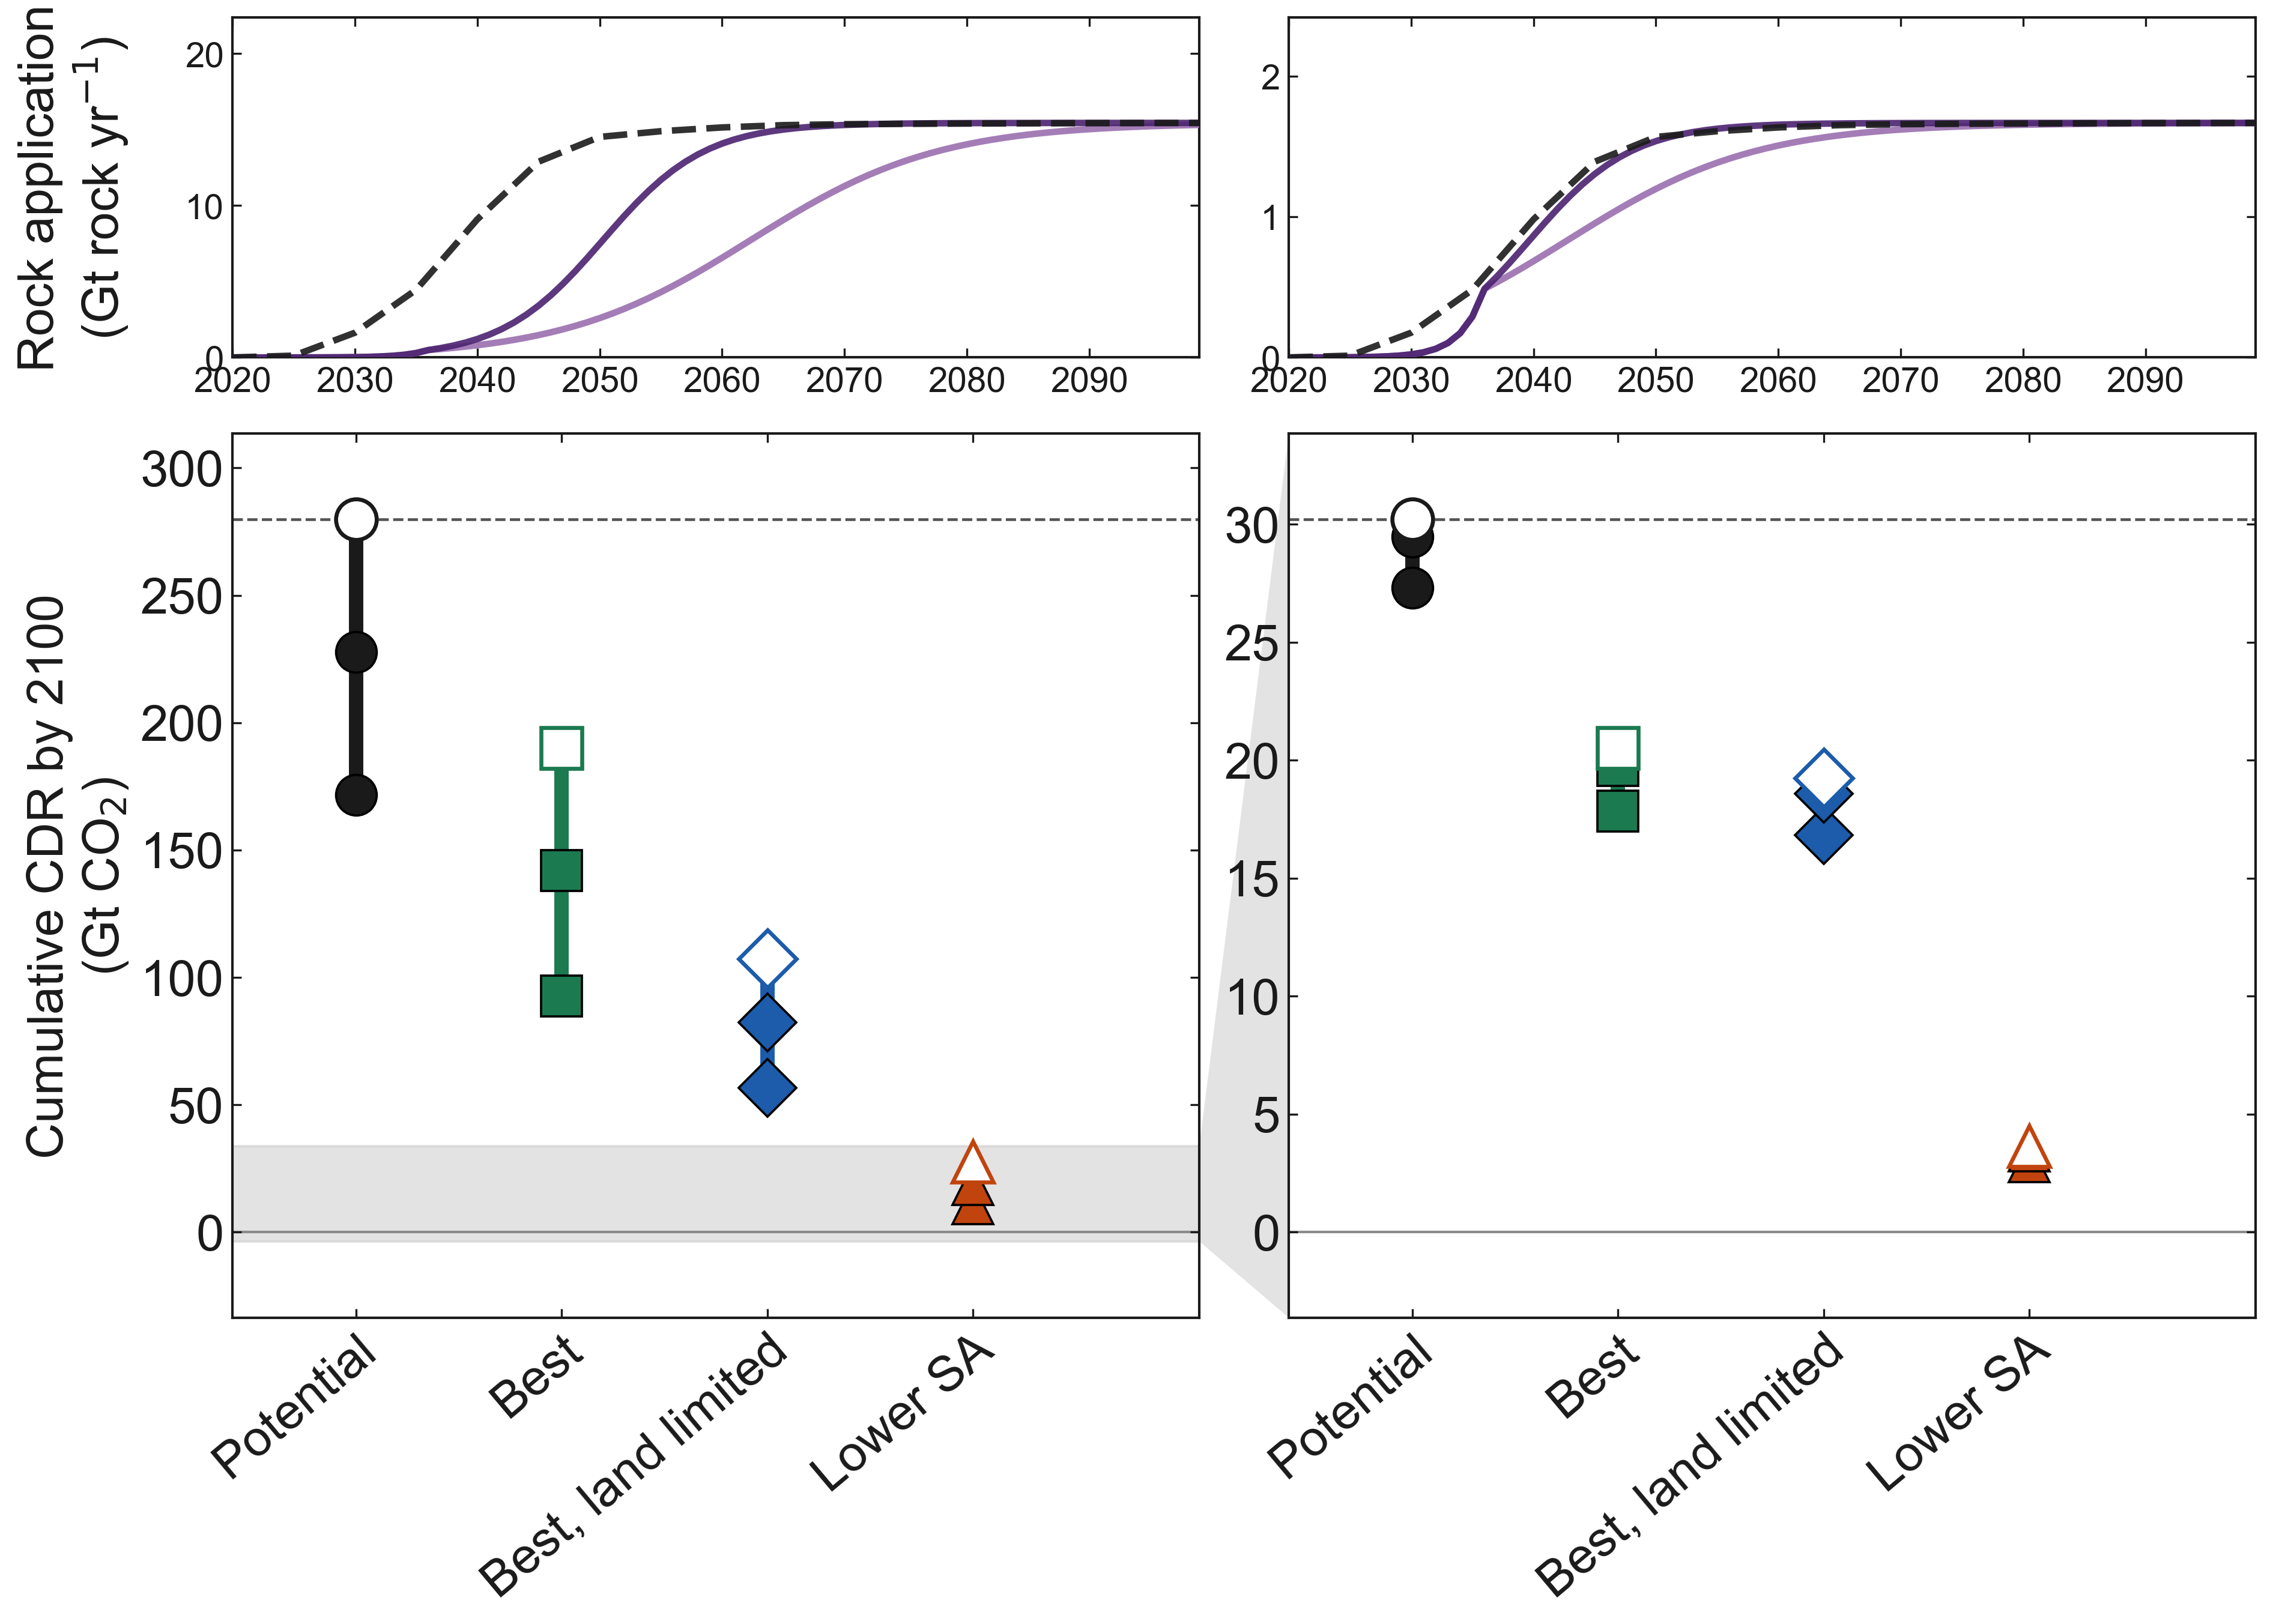

In [8]:
MAIN_CASE    = "nearterm-gcam-first10yrs"   # one of C0T0_CASES
L_CASES_MAIN = ["L_gcam", "L0.5Gt"]         # one column per L, largest first

_no_native = [L for L in L_CASES_MAIN if NATIVE_SCHEDULE.get(L) is None]
if _no_native:
    print(f"no GCAM-native schedule for {_no_native} -- plotted without the native reference")

# --- layout ---
FIG_W_M, FIG_H_M = 10.6, 7.6   # base size (in), times FIG_SCALE_M -- wider than 9.0 to absorb XPAD_R_M
FIG_SCALE_M      = 1.2
DPI_M            = 300
HEIGHT_RATIOS_M  = [1.0, 2.6]  # top:bottom
H_PAD_M, W_PAD_M = 1.4, 1.0    # tight_layout padding

# --- type sizes ---
PANEL_TITLE_FONTSIZE_M    = 20
AXIS_LABEL_FONTSIZE_M     = 20
TICK_LABEL_FONTSIZE_M     = 20
XTICK_LABEL_FONTSIZE_M    = 20
TOP_AXIS_LABEL_FONTSIZE_M = 20
TOP_TICK_LABEL_FONTSIZE_M = 14
TOP_LEGEND_FONTSIZE_M     = 13
BOTTOM_LEGEND_FONTSIZE_M  = 14
SUPTITLE_FONTSIZE_M       = 13
PANEL_LETTER_FONTSIZE_M   = 18

# --- marks ---
MARKER_SCALE_M      = 1.3    # times MS_RANGE_J
LINE_SCALE_M        = 1.15   # times LW_J
ROCK_LW_M           = 2.6
XTICK_ROTATION_M    = 40
XPAD_L_M, XPAD_R_M  = 0.6, 1.1   # bottom-row x padding (category units); right side leaves room to annotate "Low SA"
YLIM_MARGIN_M       = 0.12   # bottom-row headroom fraction
TOP_YLIM_HEADROOM_M = 1.45   # top-row headroom multiplier

# --- what to draw ---
ADD_TOP_TITLE         = False
ADD_TOP_LEGEND_M      = False
ADD_BOTTOM_LEGEND_M   = False
ADD_SUPTITLE_M        = False
ADD_PANEL_LETTERS_M   = False
SHOW_ZOOM_CONNECTOR_M = True
TOP_ZOOM_SHADE_M      = False
TOP_XLABEL_M          = ""
ZOOM_SHADE_COLOR_M    = "#c9c9c9"

K_LINE_COLOR_M = {K_LOW: "#9a6fb0", K_HIGH: "#4b2270"}   # light (slow) -> dark (fast)
K_LINE_LABEL_M = {K_LOW: "$k_{nemetMedian}$", K_HIGH: "$k_{gcam}$"}

XTICK_LABELS_M = {
    "potential_cdr_cum": "Potential",
    "best_noLandConstraint_cum": "Best",
    "best_landConstrained_cum": "Best, land limited",
    "best_hiDustrad_cum": "Lower SA",
}

ms_range_m    = MS_RANGE_J * MARKER_SCALE_M
lw_m          = LW_J * LINE_SCALE_M
x_positions_m = {q: i for i, q in enumerate(QUANTITIES)}

fig_m = plt.figure(figsize=(FIG_W_M * FIG_SCALE_M, FIG_H_M * FIG_SCALE_M), dpi=DPI_M)
gs_m  = fig_m.add_gridspec(2, len(L_CASES_MAIN), height_ratios=HEIGHT_RATIOS_M)
axes_top_m = [fig_m.add_subplot(gs_m[0, j]) for j in range(len(L_CASES_MAIN))]
axes_bot_m = [fig_m.add_subplot(gs_m[1, j]) for j in range(len(L_CASES_MAIN))]

# --- top row: global rock application vs time ---
top_ylims_m = []
for ax_t, L_case in zip(axes_top_m, L_CASES_MAIN):
    curves_m = [
        (schedule_name(MAIN_CASE, K_LOW, L_case),  K_LINE_COLOR_M[K_LOW],  "-"),
        (schedule_name(MAIN_CASE, K_HIGH, L_case), K_LINE_COLOR_M[K_HIGH], "-"),
    ]
    if NATIVE_SCHEDULE.get(L_case) is not None:
        curves_m.append((NATIVE_SCHEDULE[L_case], POTENTIAL_COLOR_J, "--"))
    ymax_m = 0.0
    for sched, color, ls in curves_m:
        ts = _rock_timeseries(sched)
        ymax_m = max(ymax_m, float(np.nanmax(ts)))
        ax_t.plot(years, ts, color=color, lw=ROCK_LW_M, ls=ls, alpha=0.9, zorder=3)
    top_ylims_m.append((0.0, ymax_m * TOP_YLIM_HEADROOM_M))

    ax_t.tick_params(which="both", direction="in", top=True, right=True,
                     labelsize=TOP_TICK_LABEL_FONTSIZE_M)
    ax_t.set_xlim(years.min(), years.max())
    if TOP_XLABEL_M:
        ax_t.set_xlabel(TOP_XLABEL_M, fontsize=TOP_AXIS_LABEL_FONTSIZE_M)
    if ADD_TOP_TITLE:
        ax_t.set_title(f"$L$ = {L_PANEL_LABEL[L_case]}", fontsize=PANEL_TITLE_FONTSIZE_M,
                       fontweight="bold")

for i, (ax_t, (lo, hi)) in enumerate(zip(axes_top_m, top_ylims_m)):
    ax_t.set_ylim(lo, hi)
    if TOP_ZOOM_SHADE_M and i < len(axes_top_m) - 1:
        ax_t.axhspan(*top_ylims_m[i + 1], color=ZOOM_SHADE_COLOR_M, alpha=0.5, zorder=0)

axes_top_m[0].set_ylabel(f"Rock application\n({ROCK_UNIT_LABEL} yr$^{{-1}}$)",
                         fontsize=TOP_AXIS_LABEL_FONTSIZE_M)

if ADD_TOP_LEGEND_M:
    top_legend_handles_m = [
        Line2D([0], [0], color=K_LINE_COLOR_M[K_LOW],  lw=ROCK_LW_M, label=K_LINE_LABEL_M[K_LOW]),
        Line2D([0], [0], color=K_LINE_COLOR_M[K_HIGH], lw=ROCK_LW_M, label=K_LINE_LABEL_M[K_HIGH]),
        Line2D([0], [0], color=POTENTIAL_COLOR_J, lw=ROCK_LW_M, ls="--", label="GCAM native"),
    ]
    axes_top_m[0].legend(handles=top_legend_handles_m, loc="upper left", frameon=False,
                         fontsize=TOP_LEGEND_FONTSIZE_M, handlelength=1.6, labelspacing=0.25,
                         borderaxespad=0.4)

# --- bottom row: cumulative CDR dumbbells ---
bot_ylims_m = []
bot_native_potential_m = []
for L_case, ax_b in zip(L_CASES_MAIN, axes_bot_m):
    ax_b.axhline(0, color=ZERO_LINE_COLOR_J, linestyle="-", linewidth=1.0, zorder=1)
    bot_native_potential_m.append(_native("potential_cdr_cum", L_case))

    row_values_m = [0.0]
    for col in QUANTITIES:
        x = x_positions_m[col]
        lo, hi = _lo_hi(col, MAIN_CASE, L_case)
        native = _native(col, L_case)
        pts = [lo, hi] if native is None else [lo, hi, native]
        line_lo, line_hi = min(pts), max(pts)
        row_values_m += [line_lo, line_hi]
        color = COLORS_J[col]

        ax_b.plot([x, x], [line_lo, line_hi], color=color, lw=lw_m, solid_capstyle="butt", zorder=3)
        ax_b.plot([x, x], [lo, hi], marker=MARKERS_J[col], ms=ms_range_m, markerfacecolor=color,
                  markeredgecolor="black", markeredgewidth=0.9, linestyle="none", zorder=4)
        if native is not None:
            ax_b.plot([x], [native], marker=MARKERS_J[col], ms=ms_range_m, markerfacecolor="white",
                      markeredgecolor=color, markeredgewidth=1.6, linestyle="none", zorder=5)

    row_min_m, row_max_m = min(row_values_m), max(row_values_m)
    pad_m = YLIM_MARGIN_M * (row_max_m - row_min_m)
    bot_ylims_m.append((min(0, row_min_m - pad_m), row_max_m + pad_m))

    ax_b.tick_params(which="both", direction="in", top=True, right=True,
                     labelsize=TICK_LABEL_FONTSIZE_M)
    ax_b.set_xlim(-XPAD_L_M, len(QUANTITIES) - 1 + XPAD_R_M)
    ax_b.set_xticks(list(x_positions_m.values()))
    ax_b.set_xticklabels([XTICK_LABELS_M[c] for c in QUANTITIES], fontsize=XTICK_LABEL_FONTSIZE_M,
                         rotation=XTICK_ROTATION_M, ha="right", rotation_mode="anchor")

axes_bot_m[0].set_ylabel(f"Cumulative CDR by 2100\n({_UNIT_LABEL[CDR_UNITS]})",
                         fontsize=AXIS_LABEL_FONTSIZE_M)

for i, (ax_b, (lo, hi)) in enumerate(zip(axes_bot_m, bot_ylims_m)):
    ax_b.set_ylim(lo, hi)
    if SHOW_ZOOM_CONNECTOR_M and i < len(axes_bot_m) - 1:
        ax_b.axhspan(*bot_ylims_m[i + 1], color=ZOOM_SHADE_COLOR_M, alpha=0.5, zorder=0)
    if bot_native_potential_m[i] is not None:
        ax_b.axhline(bot_native_potential_m[i], color=POTENTIAL_COLOR_J, linestyle="--",
                     linewidth=1.1, alpha=0.75, zorder=2)

if ADD_PANEL_LETTERS_M:
    for letter, ax in zip("abcdefgh", axes_top_m + axes_bot_m):
        ax.text(-0.02, 1.02, letter, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=PANEL_LETTER_FONTSIZE_M, fontweight="bold")

if ADD_BOTTOM_LEGEND_M:
    bot_legend_handles_m = [
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="#555555", markeredgecolor="black",
               markeredgewidth=0.9, ms=ms_range_m, label="Range endpoint ($k_{nemetMedian}$, $k_{gcam}$)"),
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor="white", markeredgecolor="#555555",
               markeredgewidth=1.6, ms=ms_range_m, label="GCAM native (reference)"),
    ]
    fig_m.legend(handles=bot_legend_handles_m, loc="lower center", ncol=2, frameon=False,
                 fontsize=BOTTOM_LEGEND_FONTSIZE_M, bbox_to_anchor=(0.5, 0.005))

if ADD_SUPTITLE_M:
    fig_m.suptitle(f"{panel_titles[MAIN_CASE]}, across $L$ scale factors", fontsize=SUPTITLE_FONTSIZE_M)

fig_m.align_ylabels([axes_top_m[0], axes_bot_m[0]])
fig_m.tight_layout(h_pad=H_PAD_M, w_pad=W_PAD_M,
                   rect=[0, 0.05 if ADD_BOTTOM_LEGEND_M else 0, 1, 0.96 if ADD_SUPTITLE_M else 1])

# bridging trapezoid between bottom panels -- after tight_layout, needs final axes positions
if SHOW_ZOOM_CONNECTOR_M:
    for i in range(len(axes_bot_m) - 1):
        ax_i, ax_next = axes_bot_m[i], axes_bot_m[i + 1]
        next_lo, next_hi = bot_ylims_m[i + 1]

        x_right_data = ax_i.get_xlim()[1]
        top_left    = fig_m.transFigure.inverted().transform(ax_i.transData.transform((x_right_data, next_hi)))
        bottom_left = fig_m.transFigure.inverted().transform(ax_i.transData.transform((x_right_data, next_lo)))
        pos_next = ax_next.get_position()
        top_right, bottom_right = (pos_next.x0, pos_next.y1), (pos_next.x0, pos_next.y0)

        funnel_m = Polygon([top_left, top_right, bottom_right, bottom_left], closed=True,
                           facecolor=ZOOM_SHADE_COLOR_M, edgecolor="none", alpha=0.5,
                           transform=fig_m.transFigure, zorder=0, clip_on=False)
        fig_m.add_artist(funnel_m)

plt.show()

if SAVE_ON:
    fname = "cumulative-cdr-mainFig.png"
    fig_m.savefig(os.path.join(savehere, "panels", fname), dpi=300, bbox_inches="tight", transparent=False)

## Summary table

In [9]:
# ============================================================
# Summary table for the main figure
# ============================================================
CDR_COL_M = f"Cumulative CDR by 2100 ({CDR_UNITS})"
EFF_COL_M = "CDR efficiency (fraction of potential)"
EFFICIENCY_QUANTITIES_M = [q for q in QUANTITIES if q != "potential_cdr_cum"]  # the non-black points

index_m, rows_m = [], []
for L_case in L_CASES_MAIN:
    points_m = [
        (K_LOW,  schedule_name(MAIN_CASE, K_LOW, L_case)),
        (K_HIGH, schedule_name(MAIN_CASE, K_HIGH, L_case)),
    ]
    # hollow marker -- same as figure's _native() uses; None = no native run at this L
    if NATIVE_SCHEDULE.get(L_case) is not None:
        points_m.append(("GCAM native", NATIVE_SCHEDULE[L_case]))
    for point, sched in points_m:
        vals = summary_df.loc[sched]
        row = {(CDR_COL_M, XTICK_LABELS_M[q]): vals[q] for q in QUANTITIES}
        row.update({(EFF_COL_M, XTICK_LABELS_M[q]): vals[q] / vals["potential_cdr_cum"]
                    for q in EFFICIENCY_QUANTITIES_M})
        index_m.append((L_case, point, sched))
        rows_m.append(row)

summary_stats_m = pd.DataFrame(rows_m, index=pd.MultiIndex.from_tuples(index_m, names=["L", "point", "schedule"]))
summary_stats_m.columns = pd.MultiIndex.from_tuples(summary_stats_m.columns)

summary_stats_m.style.format(
    {c: ("{:.1f}" if c[0] == CDR_COL_M else "{:.3f}") for c in summary_stats_m.columns}
).set_caption(f"{panel_titles[MAIN_CASE]} -- points plotted in the main figure's bottom row")

In [ ]:
# ---